In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
healthcare = pd.read_csv("healthcare_dataset.csv")

In [3]:
healthcare_clean = healthcare.copy()

**Step 1: Remove Room Number**

In [4]:
healthcare_clean = healthcare_clean.drop(columns=["Room Number"]) 

In [5]:
healthcare_clean.dtypes

Name                      str
Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount        float64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

**Step 2: Convert data type columns to Discharge Date and Date of Admission**

In [6]:
healthcare_clean["Discharge Date"] = pd.to_datetime(healthcare_clean["Discharge Date"])
healthcare_clean["Date of Admission"] = pd.to_datetime(healthcare_clean["Date of Admission"])

**Step 3: Round Billing Amount to Two Places after the Decimal**

In [7]:
healthcare_clean["Billing Amount"] = healthcare_clean["Billing Amount"].round(2)

**Step 4**: 
One Hot Encode Gender, Blood Type Admission Type and Test Results 

In [8]:
dummie_variables = pd.get_dummies(healthcare_clean[["Gender", "Blood Type", "Admission Type", "Test Results"]])

In [9]:
healthcare_clean_encoded = pd.concat([healthcare_clean, dummie_variables], axis=1)

**Step 5**
Create a new column titled age range that captured the age range of the patients

In [10]:
def age_brackets(row):
    age_ranges = row["Age"]
    if age_ranges <= 17:
        return "Minors"
    elif 18 <= age_ranges <= 34:
        return "Young Adult"
    elif 35 <= age_ranges <= 49:
        return "Middle Aged"
    elif 50 <= age_ranges <= 64:
        return "Late Middle Aged"
    elif 65 <= age_ranges <= 74:
        return "Early Retirement"
    elif 75 <= age_ranges <= 89:
        return "Senior Citizen"
    else:
        "Aging Gracefully"

In [11]:
healthcare_clean_encoded["Age Ranges"] = healthcare_clean_encoded.apply(age_brackets, axis=1)
healthcare_clean_encoded.head(5)

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,...,Blood Type_B-,Blood Type_O+,Blood Type_O-,Admission Type_Elective,Admission Type_Emergency,Admission Type_Urgent,Test Results_Abnormal,Test Results_Inconclusive,Test Results_Normal,Age Ranges
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,...,True,False,False,False,False,True,False,False,True,Young Adult
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,...,False,False,False,False,True,False,False,True,False,Late Middle Aged
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,...,False,False,False,False,True,False,False,False,True,Senior Citizen
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.78,...,False,True,False,True,False,False,True,False,False,Young Adult
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,...,False,False,False,False,False,True,True,False,False,Middle Aged


In [12]:
bins = [-np.inf, 17, 34, 49, 64, 74, 89, np.inf]
labels = ["0-17", "18-34", "35-49", "50-64", "65-74", "75-89", "90+"]

healthcare_clean_encoded["age_bracket"] = pd.cut(
    healthcare_clean_encoded["Age"], bins=bins, labels=labels
)

**Step 6: Create New Columns Admission Year and Discharge Year**
- return the year the patient was admitted and discharged
- return the month and year that the patient was admitted and discharged

In [13]:
healthcare_clean_encoded.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Admission Type', 'Discharge Date', 'Medication',
       'Test Results', 'Gender_Female', 'Gender_Male', 'Blood Type_A+',
       'Blood Type_A-', 'Blood Type_AB+', 'Blood Type_AB-', 'Blood Type_B+',
       'Blood Type_B-', 'Blood Type_O+', 'Blood Type_O-',
       'Admission Type_Elective', 'Admission Type_Emergency',
       'Admission Type_Urgent', 'Test Results_Abnormal',
       'Test Results_Inconclusive', 'Test Results_Normal', 'Age Ranges',
       'age_bracket'],
      dtype='str')

**Step 7: Create New Column Admission Year, Discharge Year Admission Month Year and Discharge Month Year that have datetime conversions**

In [14]:
healthcare_clean_encoded["Admission Year"] = healthcare_clean_encoded["Date of Admission"].dt.year
healthcare_clean_encoded["Discharge Year"] = healthcare_clean_encoded["Discharge Date"].dt.year

healthcare_clean_encoded["Admission_Month_Year"] = healthcare_clean_encoded["Date of Admission"].dt.strftime('%B %Y')
healthcare_clean_encoded["Discharge_Month_Year"] = healthcare_clean_encoded["Discharge Date"].dt.strftime('%B %Y')

**Step 8** 
- Create New COlumn Is LifeStyle Condition boolean where if a medical condition is diabetes hypertension and obesity
- Create New COlumn Is Chronic Condition boolean where medical conditon is asthma, cancer or Arthritis

In [15]:
healthcare_clean_encoded["Is_Lifestyle_Condition"] = healthcare_clean_encoded["Medical Condition"].isin(["Diabetes", "Hypertension", "Obesity"])
healthcare_clean_encoded["Is_Chronic_Condition"] = healthcare_clean_encoded["Medical Condition"].isin(["Asthma", "Cancer", "Arthritis"])

In [16]:
healthcare_clean_encoded.head(5)

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,...,Test Results_Inconclusive,Test Results_Normal,Age Ranges,age_bracket,Admission Year,Discharge Year,Admission_Month_Year,Discharge_Month_Year,Is_Lifestyle_Condition,Is_Chronic_Condition
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,...,False,True,Young Adult,18-34,2024,2024,January 2024,February 2024,False,True
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,...,True,False,Late Middle Aged,50-64,2019,2019,August 2019,August 2019,True,False
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,...,False,True,Senior Citizen,75-89,2022,2022,September 2022,October 2022,True,False
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.78,...,False,False,Young Adult,18-34,2020,2020,November 2020,December 2020,True,False
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,...,False,False,Middle Aged,35-49,2022,2022,September 2022,October 2022,False,True


In [17]:
healthcare_clean_encoded.isnull().sum()

Name                         0
Age                          0
Gender                       0
Blood Type                   0
Medical Condition            0
Date of Admission            0
Doctor                       0
Hospital                     0
Insurance Provider           0
Billing Amount               0
Admission Type               0
Discharge Date               0
Medication                   0
Test Results                 0
Gender_Female                0
Gender_Male                  0
Blood Type_A+                0
Blood Type_A-                0
Blood Type_AB+               0
Blood Type_AB-               0
Blood Type_B+                0
Blood Type_B-                0
Blood Type_O+                0
Blood Type_O-                0
Admission Type_Elective      0
Admission Type_Emergency     0
Admission Type_Urgent        0
Test Results_Abnormal        0
Test Results_Inconclusive    0
Test Results_Normal          0
Age Ranges                   0
age_bracket                  0
Admissio

In [18]:
healthcare_clean_encoded.duplicated().sum()

np.int64(534)

In [19]:
duplicate = [healthcare_clean_encoded.duplicated()]
duplicate_rows = healthcare_clean_encoded[healthcare_clean_encoded.duplicated(keep=False)]

In [20]:
for col in healthcare_clean_encoded.columns:
    pct = healthcare_clean_encoded.duplicated(subset=[col]).mean()
    print(f"{col:<25} : {pct:.2%}")

Name                      : 9.92%
Age                       : 99.86%
Gender                    : 100.00%
Blood Type                : 99.99%
Medical Condition         : 99.99%
Date of Admission         : 96.71%
Doctor                    : 27.31%
Hospital                  : 28.15%
Insurance Provider        : 99.99%
Billing Amount            : 10.34%
Admission Type            : 99.99%
Discharge Date            : 96.66%
Medication                : 99.99%
Test Results              : 99.99%
Gender_Female             : 100.00%
Gender_Male               : 100.00%
Blood Type_A+             : 100.00%
Blood Type_A-             : 100.00%
Blood Type_AB+            : 100.00%
Blood Type_AB-            : 100.00%
Blood Type_B+             : 100.00%
Blood Type_B-             : 100.00%
Blood Type_O+             : 100.00%
Blood Type_O-             : 100.00%
Admission Type_Elective   : 100.00%
Admission Type_Emergency  : 100.00%
Admission Type_Urgent     : 100.00%
Test Results_Abnormal     : 100.00%
Test R

**Return all Rows with Duplicate Names and Remove Them, then Remove Name as a column**

In [21]:
duplicate_rows_name = healthcare_clean_encoded[healthcare_clean_encoded.duplicated(subset=["Name"], keep="first")]

healthcare_clean_encoded = healthcare_clean_encoded.drop_duplicates(subset=["Name"], keep="first")

healthcare_clean_encoded = healthcare_clean_encoded.drop(columns=["Name"])

**Check for Outliers in the Age Column**

In [22]:
target_col = "Age"

Q1 = healthcare_clean_encoded["Age"].quantile(0.25)
Q3 = healthcare_clean_encoded["Age"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = healthcare_clean_encoded[(healthcare_clean_encoded[target_col] < lower_bound) | healthcare_clean_encoded[target_col] > upper_bound]

print(f"Total outliers found via IQR: {len(outliers_iqr)}")
print(f"Valid range for data: {lower_bound:.2f} to {upper_bound:.2f}")

Total outliers found via IQR: 0
Valid range for data: -14.50 to 117.50


**Check for Outliers in the Billing Amount Column**

In [23]:
target_col_1 = "Billing Amount"

Q1 = healthcare_clean_encoded["Billing Amount"].quantile(0.25)
Q3 = healthcare_clean_encoded["Billing Amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR 
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = healthcare_clean_encoded[(healthcare_clean_encoded[target_col] < lower_bound) | healthcare_clean_encoded[target_col] > upper_bound]

print(f"Total outliers found via IQR: {len(outliers_iqr)}")
print(f"Valid range for data: {lower_bound:.2f} to {upper_bound:.2f}")

Total outliers found via IQR: 0
Valid range for data: -23682.48 to 74775.88


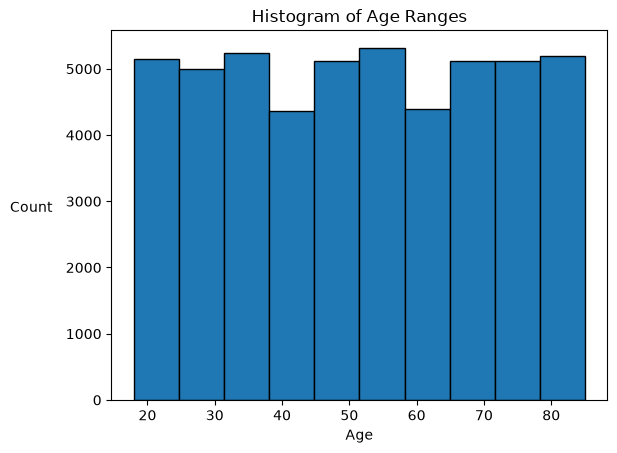

In [24]:
plt.hist(healthcare_clean_encoded["Age"], bins=10, edgecolor="black")
plt.title("Histogram of Age Ranges")
plt.xlabel("Age")
plt.ylabel("Count", rotation=0, labelpad=25)
plt.show()

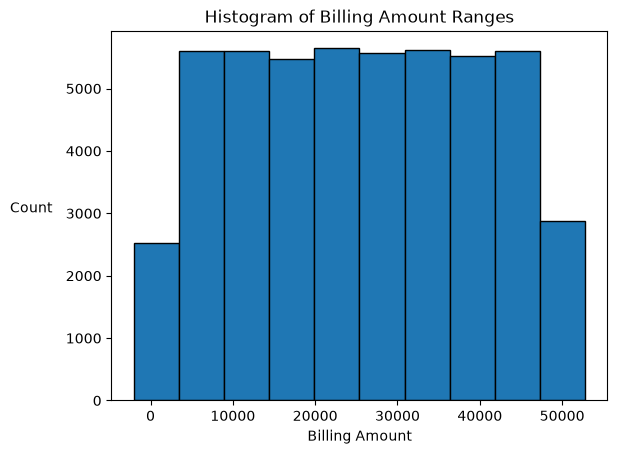

In [25]:
plt.hist(healthcare_clean_encoded["Billing Amount"], bins=10, edgecolor="black")
plt.title("Histogram of Billing Amount Ranges")
plt.xlabel("Billing Amount")
plt.ylabel("Count", rotation=0, labelpad=25)
plt.show()

In [26]:
healthcare_clean_encoded[["Billing Amount", "Age"]].describe()

,Billing Amount,Age
count,49992.000000,49992.000000
mean,25555.725254,51.579453
std,14215.988131,19.581816
min,-2008.490000,18.000000
25%,13239.407500,35.000000
50%,25541.305000,52.000000
75%,37853.997500,68.000000
max,52764.280000,85.000000


**Filter out values with Billing Amount less than 0**

In [27]:
healthcare_clean_encoded = healthcare_clean_encoded[healthcare_clean_encoded["Billing Amount"] >= 0]

**Return Composition of Patient By Gender**

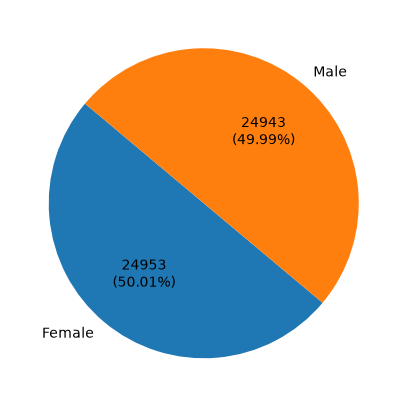

In [28]:
gender_counts = healthcare_clean_encoded["Gender"].value_counts()
gender_sum = gender_counts.sum()

def make_autopct(values):
    def my_autopct(pct):
        val = int(round(pct * gender_sum / 100.0))
        return f'{val}\n({pct:.2f}%)'
    return my_autopct

plt.figure(figsize=(5, 8))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct=make_autopct(gender_counts),
    startangle=140
)
plt.show()

**Return Admissions of Patient By Medical Condition Per Year**

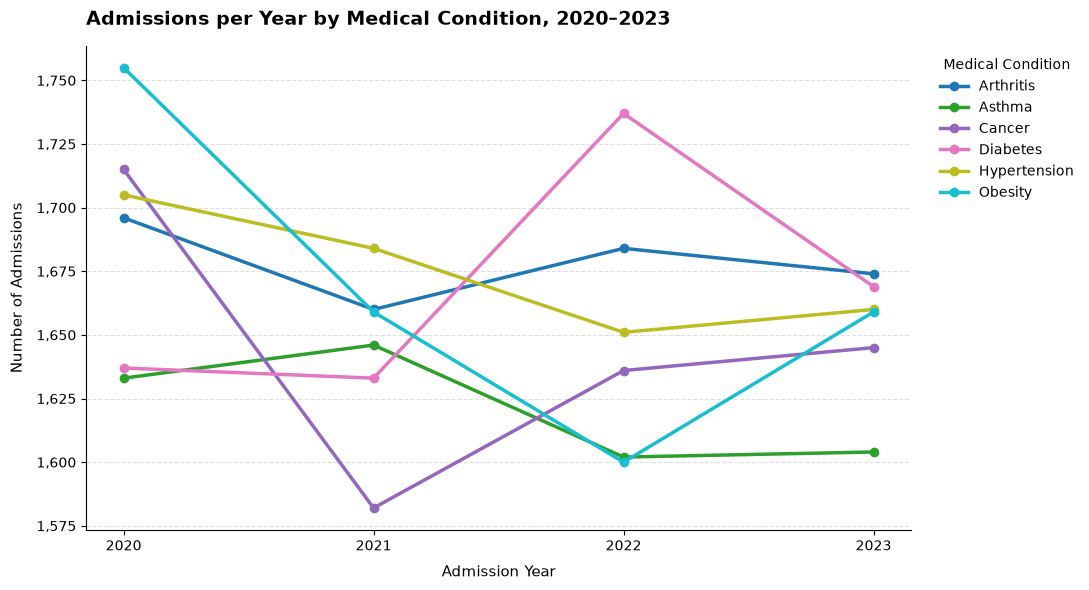

In [29]:
import matplotlib.ticker as mtick

year_medical_conditions = (
    healthcare_clean_encoded
    .groupby(["Medical Condition", "Admission Year"])
    .size()
    .unstack(fill_value=0)
)

full_years = [2020, 2021, 2022, 2023]
data = year_medical_conditions[full_years]

ax = data.T.plot(kind="line", marker="o", linewidth=2.5, markersize=6,
                 figsize=(11, 6), colormap="tab10")

ax.set_title("Admissions per Year by Medical Condition, 2020–2023",
             fontsize=14, fontweight="bold", loc="left", pad=15)
ax.set_xlabel("Admission Year", fontsize=11, labelpad=8)
ax.set_ylabel("Number of Admissions", fontsize=11, labelpad=8)

ax.set_xticks(full_years)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="Medical Condition", frameon=False,
          bbox_to_anchor=(1.02, 1), loc="upper left")

for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

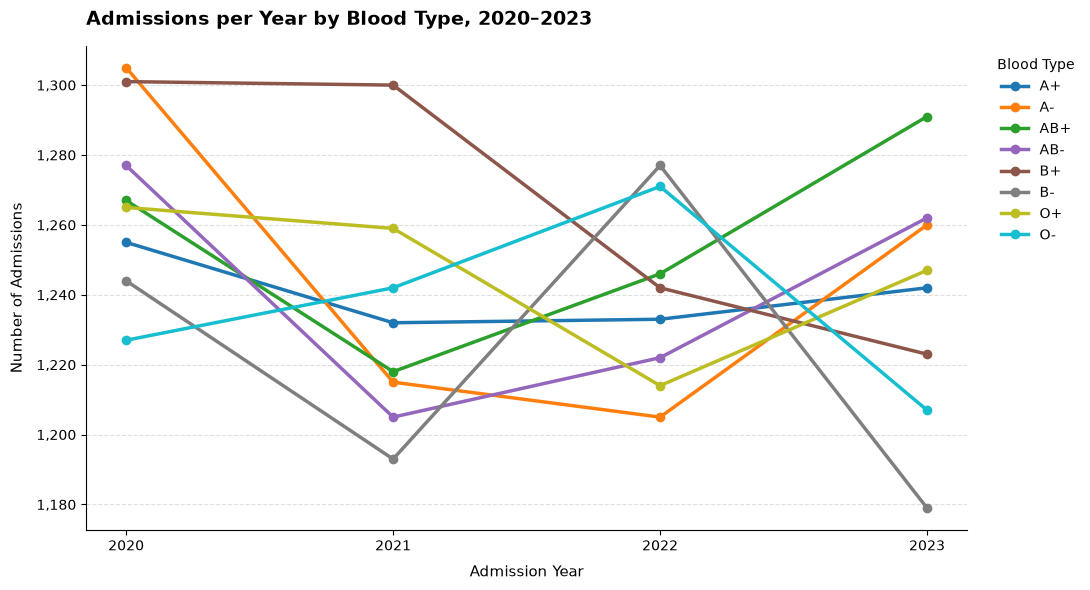

In [30]:
blood_type_year = (
    healthcare_clean_encoded
    .groupby(["Blood Type", "Admission Year"])
    .size()
    .unstack(fill_value=0)
)

full_years = [2020, 2021, 2022, 2023]
data = blood_type_year[full_years]

ax = data.T.plot(kind="line", marker="o", linewidth=2.5, markersize=6,
                 figsize=(11, 6), colormap="tab10")

ax.set_title("Admissions per Year by Blood Type, 2020–2023",
             fontsize=14, fontweight="bold", loc="left", pad=15)
ax.set_xlabel("Admission Year", fontsize=11, labelpad=8)
ax.set_ylabel("Number of Admissions", fontsize=11, labelpad=8)

ax.set_xticks(full_years)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="Blood Type", frameon=False,
          bbox_to_anchor=(1.02, 1), loc="upper left")

for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

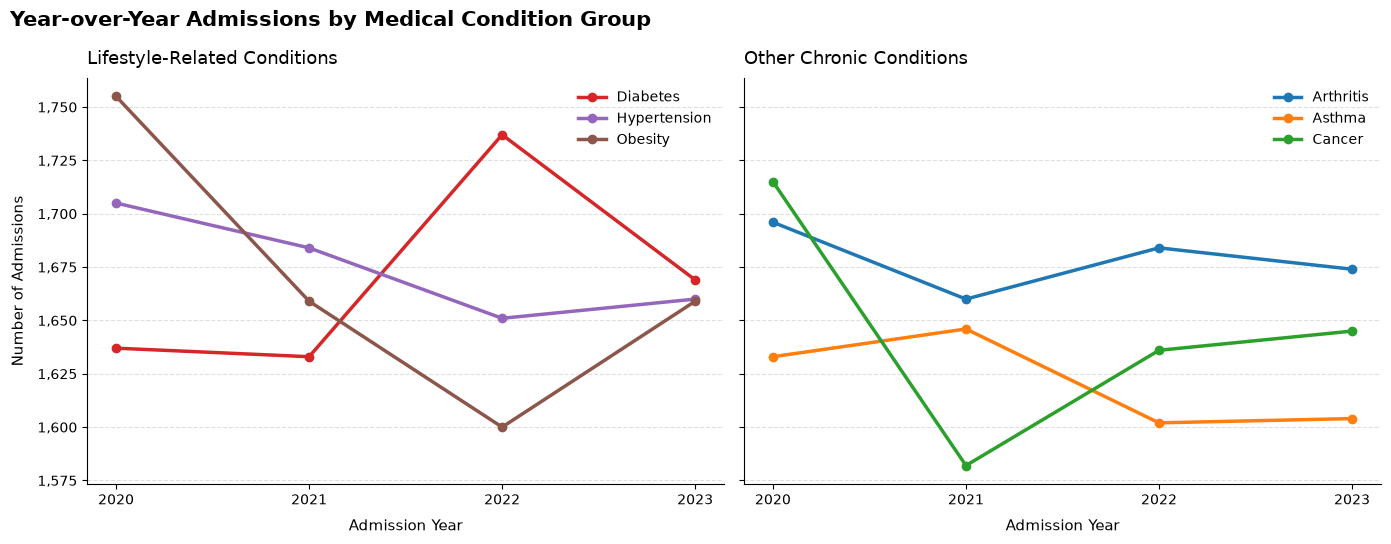

In [31]:
plt.figure(figsize=(12, 6))
colors = plt.colormaps["tab10"]
full_years = [2020, 2021, 2022, 2023]
data = year_medical_conditions[full_years]
conditions = list(data.index)

groups = {
    "Lifestyle-Related Conditions": ["Diabetes", "Hypertension", "Obesity"],
    "Other Chronic Conditions": ["Arthritis", "Asthma", "Cancer"],
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for ax, (title, group) in zip(axes, groups.items()):
    for condition in group:
        ax.plot(full_years, data.loc[condition],
                marker="o", linewidth=2.5, markersize=6,
                color=colors(conditions.index(condition)), label=condition)

    ax.set_title(title, fontsize=13, loc="left", pad=10)
    ax.set_xlabel("Admission Year", fontsize=11, labelpad=8)
    ax.set_xticks(full_years)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(frameon=False, fontsize=10, loc="upper right")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("Number of Admissions", fontsize=11, labelpad=8)

fig.suptitle("Year-over-Year Admissions by Medical Condition Group",
             fontsize=15, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

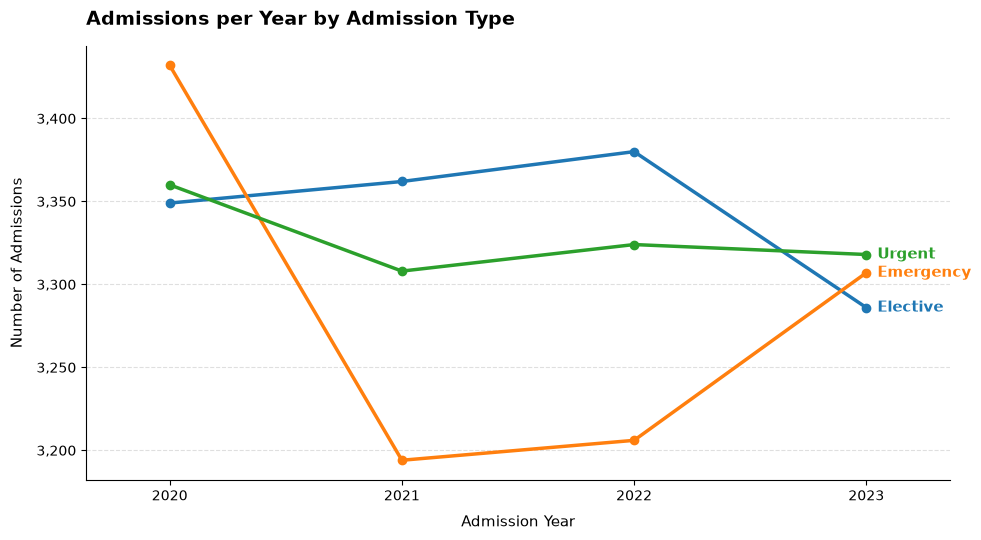

In [32]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

admission_type_year = (
    healthcare_clean_encoded
    .groupby(["Admission Type", "Admission Year"])
    .size()
    .unstack(fill_value=0)
)

# Keep only full years (2019 and 2024 look partial)
full_years = [2020, 2021, 2022, 2023]
data = admission_type_year[full_years]

colors = plt.colormaps["tab10"]
fig, ax = plt.subplots(figsize=(10, 5.5))

for i, admission_type in enumerate(data.index):
    y = data.loc[admission_type]
    ax.plot(full_years, y, marker="o", linewidth=2.5, markersize=6,
            color=colors(i))
    # Label each line at its right end instead of using a legend
    ax.annotate(f"{admission_type}", xy=(full_years[-1], y.iloc[-1]),
                xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=11, color=colors(i), fontweight="bold")

ax.set_title("Admissions per Year by Admission Type",
             fontsize=14, fontweight="bold", loc="left", pad=15)
ax.set_xlabel("Admission Year", fontsize=11, labelpad=8)
ax.set_ylabel("Number of Admissions", fontsize=11, labelpad=8)

ax.set_xticks(full_years)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Remove chart junk
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

ax.margins(x=0.12)  # room for the end labels
plt.tight_layout()
plt.show()

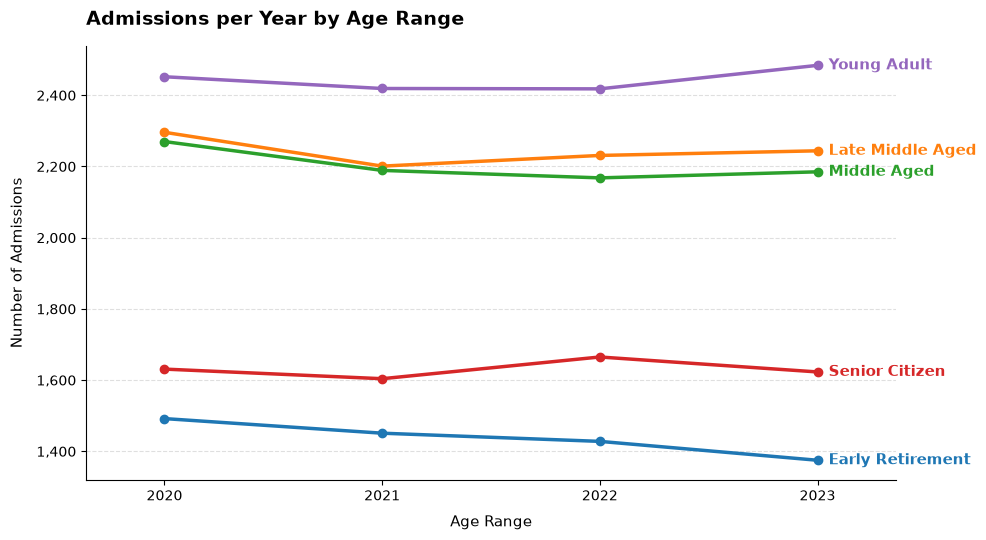

In [33]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

age_range_year = (
    healthcare_clean_encoded
    .groupby(["Age Ranges", "Admission Year"])
    .size()
    .unstack(fill_value=0)
)

# Keep only full years (2019 and 2024 look partial)
full_years = [2020, 2021, 2022, 2023]
data = age_range_year[full_years]

colors = plt.colormaps["tab10"]
fig, ax = plt.subplots(figsize=(10, 5.5))

for i, admission_type in enumerate(data.index):
    y = data.loc[admission_type]
    ax.plot(full_years, y, marker="o", linewidth=2.5, markersize=6,
            color=colors(i))
    # Label each line at its right end instead of using a legend
    ax.annotate(f"{admission_type}", xy=(full_years[-1], y.iloc[-1]),
                xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=11, color=colors(i), fontweight="bold")

ax.set_title("Admissions per Year by Age Range",
             fontsize=14, fontweight="bold", loc="left", pad=15)
ax.set_xlabel("Age Range", fontsize=11, labelpad=8)
ax.set_ylabel("Number of Admissions", fontsize=11, labelpad=8)

ax.set_xticks(full_years)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Remove chart junk
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

ax.margins(x=0.12)  # room for the end labels
plt.tight_layout()
plt.show()

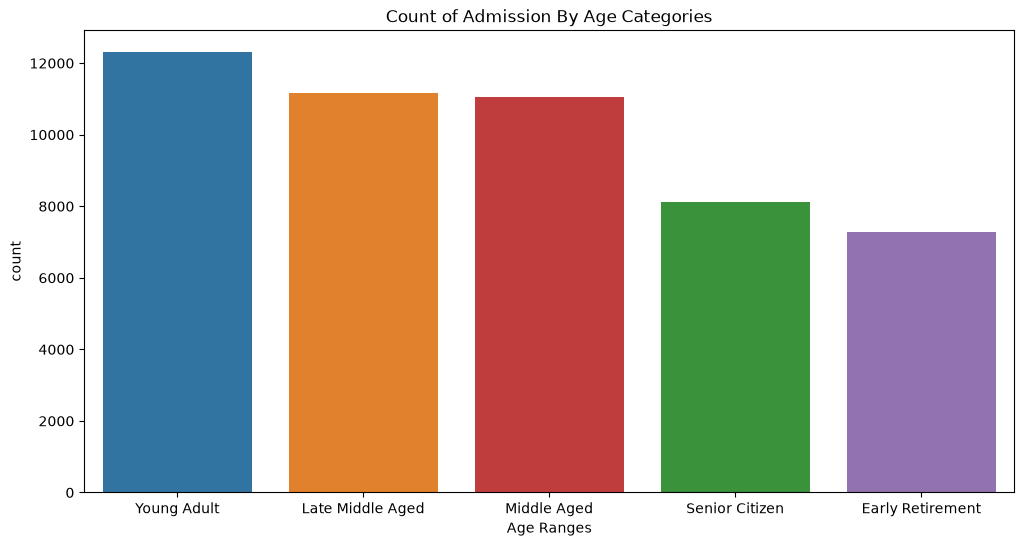

In [34]:
order1 = healthcare_clean_encoded["Age Ranges"].value_counts().index

plt.figure(figsize=(12, 6))
sns.countplot(data=healthcare_clean_encoded, x="Age Ranges", hue="Age Ranges", order=order1)
plt.title("Count of Admission By Age Categories")
plt.show()

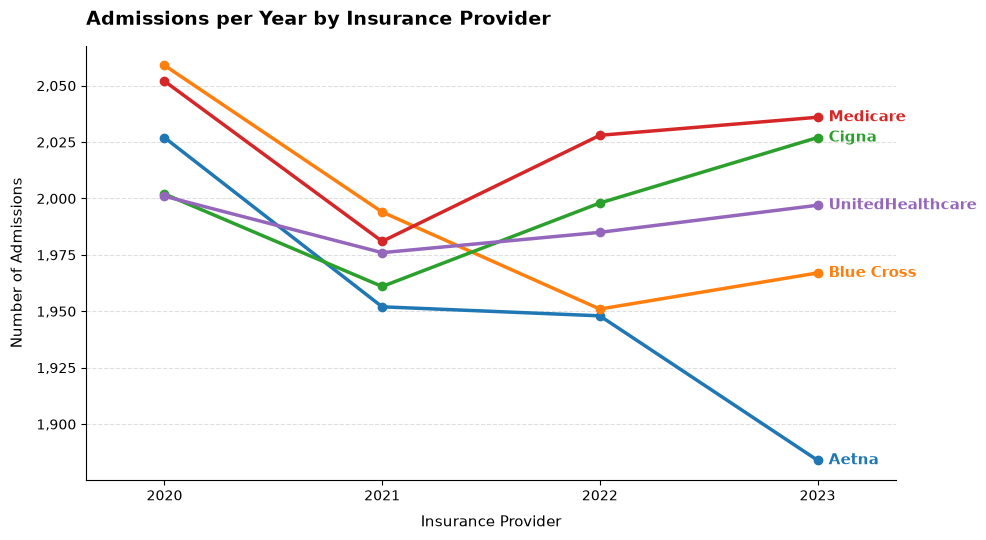

In [35]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

insurnace_providers_year = (
    healthcare_clean_encoded
    .groupby(["Insurance Provider", "Admission Year"])
    .size()
    .unstack(fill_value=0)
)

# Keep only full years (2019 and 2024 look partial)
full_years = [2020, 2021, 2022, 2023]
data = insurnace_providers_year[full_years]

colors = plt.colormaps["tab10"]
fig, ax = plt.subplots(figsize=(10, 5.5))

for i, admission_type in enumerate(data.index):
    y = data.loc[admission_type]
    ax.plot(full_years, y, marker="o", linewidth=2.5, markersize=6,
            color=colors(i))
    # Label each line at its right end instead of using a legend
    ax.annotate(f"{admission_type}", xy=(full_years[-1], y.iloc[-1]),
                xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=11, color=colors(i), fontweight="bold")

ax.set_title("Admissions per Year by Insurance Provider",
             fontsize=14, fontweight="bold", loc="left", pad=15)
ax.set_xlabel("Insurance Provider", fontsize=11, labelpad=8)
ax.set_ylabel("Number of Admissions", fontsize=11, labelpad=8)

ax.set_xticks(full_years)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Remove chart junk
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

ax.margins(x=0.12)  # room for the end labels
plt.tight_layout()
plt.show()

In [36]:
healthcare_clean_encoded

,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Admission Type,...,Test Results_Inconclusive,Test Results_Normal,Age Ranges,age_bracket,Admission Year,Discharge Year,Admission_Month_Year,Discharge_Month_Year,Is_Lifestyle_Condition,Is_Chronic_Condition
0,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,Urgent,...,False,True,Young Adult,18-34,2024,2024,January 2024,February 2024,False,True
1,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,Emergency,...,True,False,Late Middle Aged,50-64,2019,2019,August 2019,August 2019,True,False
2,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,Emergency,...,False,True,Senior Citizen,75-89,2022,2022,September 2022,October 2022,True,False
3,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.78,Elective,...,False,False,Young Adult,18-34,2020,2020,November 2020,December 2020,True,False
4,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,Urgent,...,False,False,Middle Aged,35-49,2022,2022,September 2022,October 2022,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,64,Male,O+,Hypertension,2022-06-28,Arthur Fleming,"and Williams, Brown Mckenzie",Blue Cross,24747.35,Emergency,...,True,False,Late Middle Aged,50-64,2022,2022,June 2022,July 2022,True,False
49996,69,Male,B+,Cancer,2020-04-04,Mark Moore,Wise Ltd,Medicare,40657.58,Elective,...,False,False,Early Retirement,65-74,2020,2020,April 2020,April 2020,False,True
49997,73,Male,O-,Cancer,2023-09-08,Deborah Sutton,"Moreno Murphy, Griffith and",Blue Cross,8441.15,Elective,...,False,False,Early Retirement,65-74,2023,2023,September 2023,September 2023,False,True
49998,81,Male,B-,Cancer,2020-10-13,Mary Bartlett,Sons Smith and,Blue Cross,34934.28,Elective,...,False,False,Senior Citizen,75-89,2020,2020,October 2020,October 2020,False,True


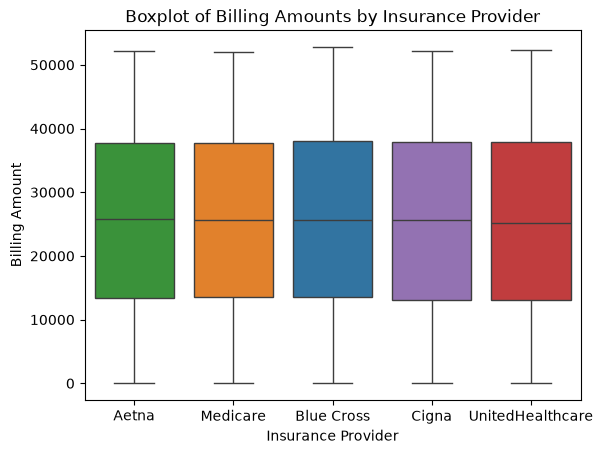

In [37]:
order2 = (healthcare_clean_encoded
         .groupby("Insurance Provider")["Billing Amount"]
         .median()
         .sort_values(ascending=False)
         .index)

sns.boxplot(data=healthcare_clean_encoded, x="Insurance Provider", y="Billing Amount", hue="Insurance Provider", order=order2)
plt.title("Boxplot of Billing Amounts by Insurance Provider")
plt.show()

<Figure size 1200x700 with 0 Axes>

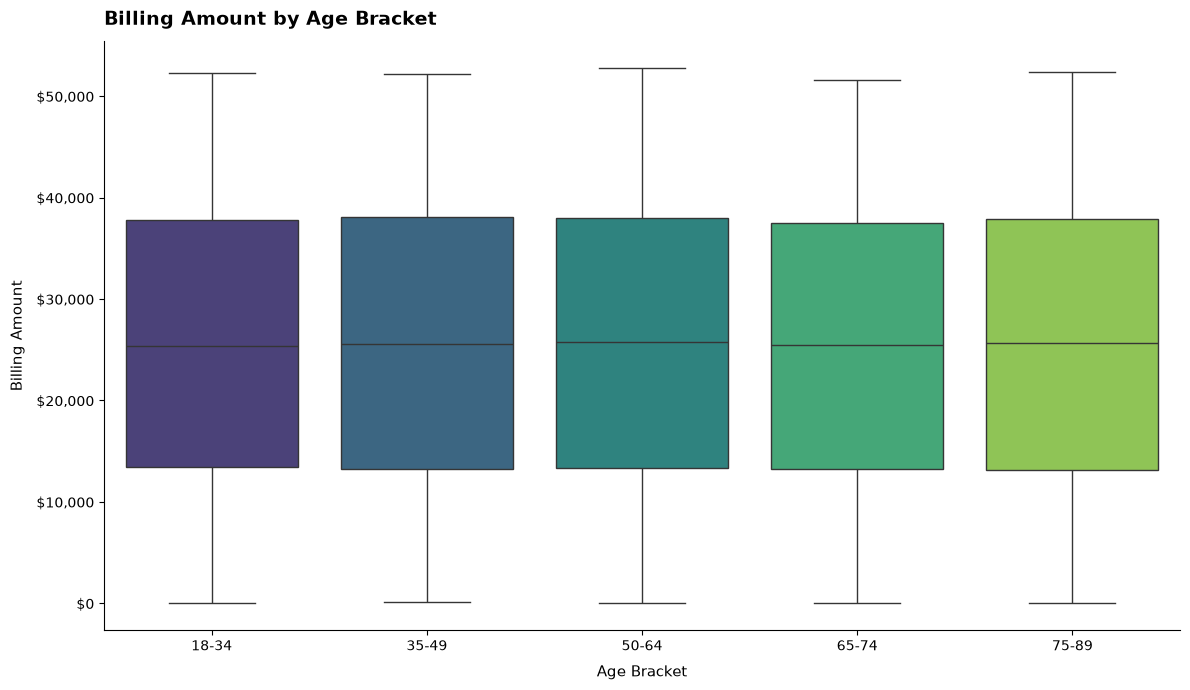

In [44]:
plt.figure(figsize=(12, 7))

present = healthcare_clean_encoded["age_bracket"].value_counts()
order3 = [b for b in labels if present.get(b, 0) > 0]

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=healthcare_clean_encoded, x="age_bracket", y="Billing Amount",
            hue="age_bracket", order=order3, hue_order=order3,
            palette="viridis", legend=False,
            dodge=False, width=0.8, ax=ax)

ax.set_title("Billing Amount by Age Bracket",
             fontsize=14, fontweight="bold", loc="left", pad=12)
ax.set_xlabel("Age Bracket", fontsize=11, labelpad=8)
ax.set_ylabel("Billing Amount", fontsize=11, labelpad=8)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

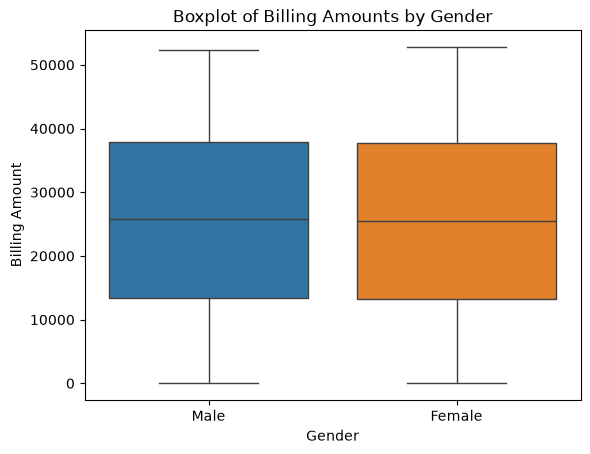

In [46]:
order3 = (healthcare_clean_encoded
         .groupby("Gender")["Billing Amount"]
         .median()
         .sort_values(ascending=False)
         .index)

sns.boxplot(data=healthcare_clean_encoded, x="Gender", y="Billing Amount", hue="Gender", order=order3)
plt.title("Boxplot of Billing Amounts by Gender")
plt.show()

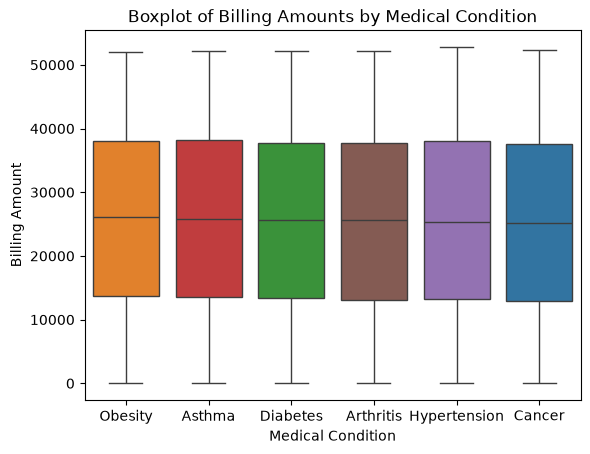

In [50]:
order4 = (healthcare_clean_encoded
         .groupby("Medical Condition")["Billing Amount"]
         .median()
         .sort_values(ascending=False)
         .index)

sns.boxplot(data=healthcare_clean_encoded, x="Medical Condition", y="Billing Amount", hue="Medical Condition", order=order4)
plt.title("Boxplot of Billing Amounts by Medical Condition")
plt.show()

In [51]:
healthcare_clean_encoded.dtypes

Age                                   int64
Gender                                  str
Blood Type                              str
Medical Condition                       str
Date of Admission            datetime64[us]
Doctor                                  str
Hospital                                str
Insurance Provider                      str
Billing Amount                      float64
Admission Type                          str
Discharge Date               datetime64[us]
Medication                              str
Test Results                            str
Gender_Female                          bool
Gender_Male                            bool
Blood Type_A+                          bool
Blood Type_A-                          bool
Blood Type_AB+                         bool
Blood Type_AB-                         bool
Blood Type_B+                          bool
Blood Type_B-                          bool
Blood Type_O+                          bool
Blood Type_O-                   

In [72]:
abnormal_tests = pd.crosstab(
    healthcare_clean_encoded["Medical Condition"],
    healthcare_clean_encoded["Test Results_Abnormal"]
).reindex(columns=[True, False])

abnormal_tests["Total"] = abnormal_tests[True] + abnormal_tests[False]
abnormal_tests["% Abnormal"] = (abnormal_tests[True] / abnormal_tests["Total"] * 100).round(2)

abnormal_tests.sort_values(by=["% Abnormal"], ascending=False)

Test Results_Abnormal,True,False,Total,% Abnormal
Medical Condition,,,,
Arthritis,2905,5524,8429,34.46
Obesity,2813,5461,8274,34.00
Diabetes,2824,5540,8364,33.76
Cancer,2790,5486,8276,33.71
Hypertension,2715,5585,8300,32.71
Asthma,2689,5564,8253,32.58


In [73]:
inconclusive_tests = pd.crosstab(
    healthcare_clean_encoded["Medical Condition"],
    healthcare_clean_encoded["Test Results_Inconclusive"]
).reindex(columns=[True, False])

inconclusive_tests["Total"] = inconclusive_tests[True] + inconclusive_tests[False]
inconclusive_tests["% Inconclusive"] = (inconclusive_tests[True] / inconclusive_tests["Total"] * 100).round(2)

inconclusive_tests.sort_values(by=["% Inconclusive"], ascending=False)

Test Results_Inconclusive,True,False,Total,% Inconclusive
Medical Condition,,,,
Hypertension,2781,5519,8300,33.51
Cancer,2745,5531,8276,33.17
Arthritis,2787,5642,8429,33.06
Diabetes,2756,5608,8364,32.95
Obesity,2721,5553,8274,32.89
Asthma,2713,5540,8253,32.87
